In [1]:
import numpy as np
import matplotlib.pyplot as plt

import taichi as ti
ti.init(
    arch=ti.cpu,
    default_fp=ti.f64,
    cpu_max_num_threads=1,
    offline_cache=False,
    debug=True,
)

import jax
jax.config.update("jax_enable_x64", True)
jax.config.update("jax_platform_name", "cpu")


[Taichi] version 1.7.4, llvm 15.0.4, commit b4b956fd, linux, python 3.12.14
[Taichi] Starting on arch=x64


[I 09/29/26 15:21:35.443 613555] [shell.py:_shell_pop_print@23] Graphical python shell detected, using wrapped sys.stdout


In [2]:
from tiwave.waveforms import IMRPhenomXAS
from ripplegw.waveforms.IMRPhenomXAS import gen_IMRPhenomXAS_hphctf
import bilby


In [3]:
rate = 4096
duration = 4
num = rate * duration
dt = 1/rate
df = 1/duration
fref = 20.0
fmin = 20.0
fmax = 2048.0
appro = "IMRPhenomXAS"

freqs = np.fft.rfftfreq(num, dt)
mask = (freqs >= fmin) * (freqs <= fmax)
freqs = freqs[mask]
display(freqs)

params = dict(
    mass_1=36.0,
    mass_2=29.0,
    luminosity_distance=800.0,
    reference_phase=1.2,
    chi_1=-0.4,
    chi_2=0.02,
    inclination=0.4,
    coalescence_time=10.5,
    # coalescence_time=0.0,
)
params = bilby.gw.conversion.generate_mass_parameters(params)
display(params)


array([  20.  ,   20.25,   20.5 , ..., 2047.5 , 2047.75, 2048.  ],
      shape=(8113,))

{'mass_1': 36.0,
 'mass_2': 29.0,
 'luminosity_distance': 800.0,
 'reference_phase': 1.2,
 'chi_1': -0.4,
 'chi_2': 0.02,
 'inclination': 0.4,
 'coalescence_time': 10.5,
 'chirp_mass': 28.09555579546043,
 'total_mass': 65.0,
 'symmetric_mass_ratio': np.float64(0.24710059171597634),
 'mass_ratio': 0.8055555555555556}

In [4]:
wf_tiwave = IMRPhenomXAS(
    frequencies = freqs,
    reference_frequency = fref,
)
wf_tiwave.update_waveform(params)

/home/nrui/disk_ext/workspace/tiwave/tiwave/waveforms/base_waveform.py:69: UserWarning: check_parameters is disable, make sure all parameters passed in are valid.
  warnings.warn(
<unknown>:10: SyntaxWarning: invalid escape sequence '\p'


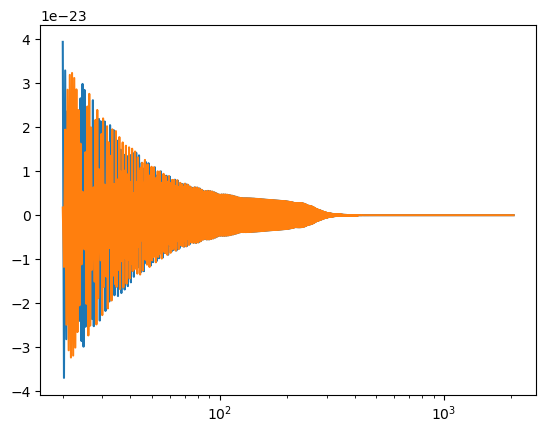

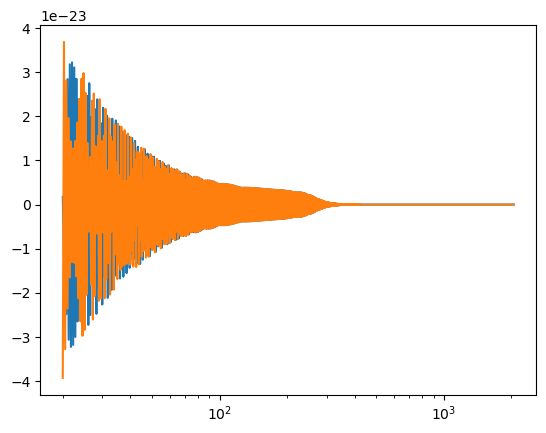

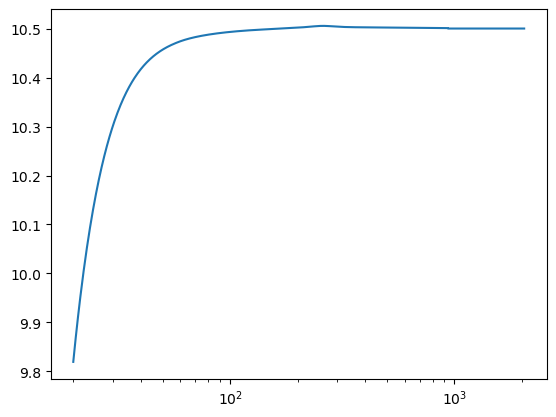

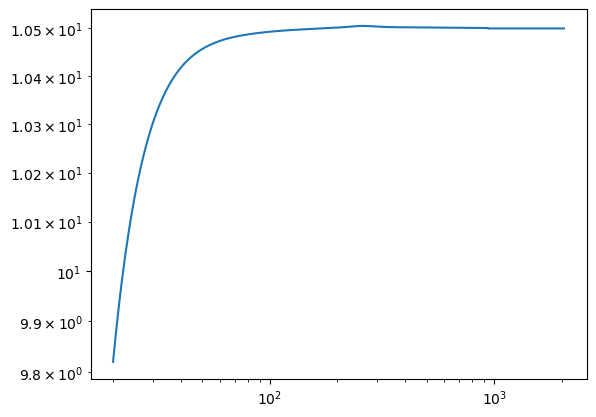

In [5]:
wf_ti = wf_tiwave.waveform_container_numpy
wf_ti['plus'] *=  np.exp(-1j * 2 * np.pi * freqs * params['coalescence_time'])
wf_ti['cross'] *= np.exp(-1j * 2 * np.pi * freqs * params['coalescence_time'])
wf_ti['tf'] += params['coalescence_time']

plt.figure()
plt.semilogx(freqs, wf_ti['plus'].real)
plt.semilogx(freqs, wf_ti['plus'].imag)

plt.figure()
plt.semilogx(freqs, wf_ti['cross'].real)
plt.semilogx(freqs, wf_ti['cross'].imag)

plt.figure()
plt.semilogx(freqs, wf_ti['tf'])

plt.figure()
plt.loglog(freqs, np.abs(wf_ti['tf']))



In [6]:
params_rp = np.array(
    [
        params['chirp_mass'],
        params['symmetric_mass_ratio'],
        params['chi_1'],
        params['chi_2'],
        params['luminosity_distance'],
        params['coalescence_time'],
        params['reference_phase'],
        params['inclination'],
    ]
    )
wf_rp = gen_IMRPhenomXAS_hphctf(freqs, params_rp, fref)

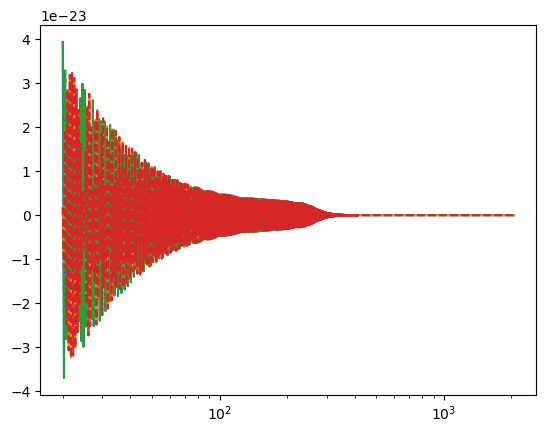

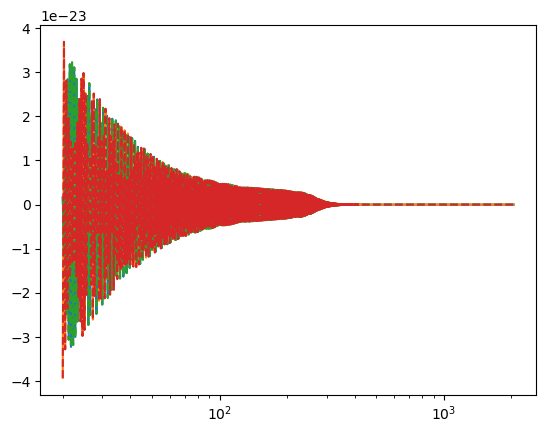

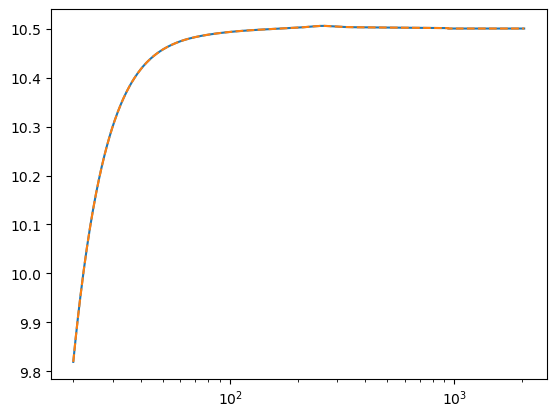

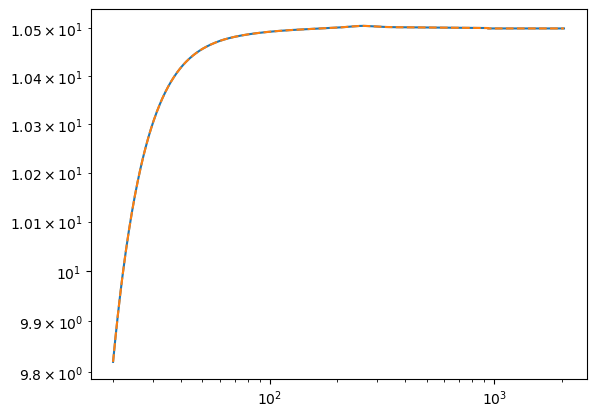

In [7]:

plt.figure()
plt.semilogx(freqs, wf_rp[0].real)
plt.semilogx(freqs, wf_rp[0].imag)
plt.semilogx(freqs, wf_ti['plus'].real, linestyle='dashed')
plt.semilogx(freqs, wf_ti['plus'].imag, linestyle='dashed')

plt.figure()
plt.semilogx(freqs, wf_rp[1].real)
plt.semilogx(freqs, wf_rp[1].imag)
plt.semilogx(freqs, wf_ti['cross'].real, linestyle='dashed')
plt.semilogx(freqs, wf_ti['cross'].imag, linestyle='dashed')

plt.figure()
plt.semilogx(freqs, wf_rp[2])
plt.semilogx(freqs, wf_ti['tf'], linestyle='dashed')

plt.figure()
plt.loglog(freqs, np.abs(wf_rp[2]))
plt.loglog(freqs, np.abs(wf_ti['tf']), linestyle='dashed')


In [8]:
np.testing.assert_allclose(wf_ti['plus'], wf_rp[0])
np.testing.assert_allclose(wf_ti['cross'], wf_rp[1])
np.testing.assert_allclose(wf_ti['tf'], wf_rp[2])

In [9]:
from tiwave.waveforms import IMRPhenomXHM
from ripplegw.waveforms.IMRPhenomXHM import gen_IMRPhenomXHM_hphctf_modes

In [10]:
high_modes = ("21", "33", "32", "44")
all_modes = ("22",) + high_modes

wf_tiwave_hm = IMRPhenomXHM(
    frequencies=freqs,
    reference_frequency=fref,
    high_modes=high_modes,
    combine_modes=False,
    include_tf=True,
)
wf_tiwave_hm.update_waveform(params)
wf_ti_hm_raw = wf_tiwave_hm.waveform_container.to_numpy()
wf_ti_hm = {}
for mode in all_modes:
    wf_ti_hm[mode] = {
        "plus": wf_ti_hm_raw[mode]["plus"][:, 0] + 1j * wf_ti_hm_raw[mode]["plus"][:, 1],
        "cross": wf_ti_hm_raw[mode]["cross"][:, 0] + 1j * wf_ti_hm_raw[mode]["cross"][:, 1],
        "tf": np.array(wf_ti_hm_raw[mode]["tf"]),
    }
    # coalescence time shift (tiwave does not apply it internally);
    wf_ti_hm[mode]["plus"] *= np.exp(-1j * 2 * np.pi * freqs * params["coalescence_time"])
    wf_ti_hm[mode]["cross"] *= np.exp(-1j * 2 * np.pi * freqs * params["coalescence_time"])
    wf_ti_hm[mode]["tf"] += params["coalescence_time"]


/home/nrui/disk_ext/workspace/tiwave/tiwave/waveforms/IMRPhenomXHM.py:7038: UserWarning: Mode 32 has relatively large numerical errors with lalsim, especially for high spin and extreme mass ratio. See examples/checking_waveforms.ipynb for more details. Please make sure these errors are acceptable in your cases before using.
  warnings.warn(
/home/nrui/disk_ext/workspace/tiwave/tiwave/waveforms/IMRPhenomXHM.py:7045: UserWarning: `tf` is required for mode 32, since the derivative of phase for merge-ringdown of mode 32 is obtained through numerical difference, if may not reliable for some cases.
  warnings.warn(
<unknown>:10: SyntaxWarning: invalid escape sequence '\p'


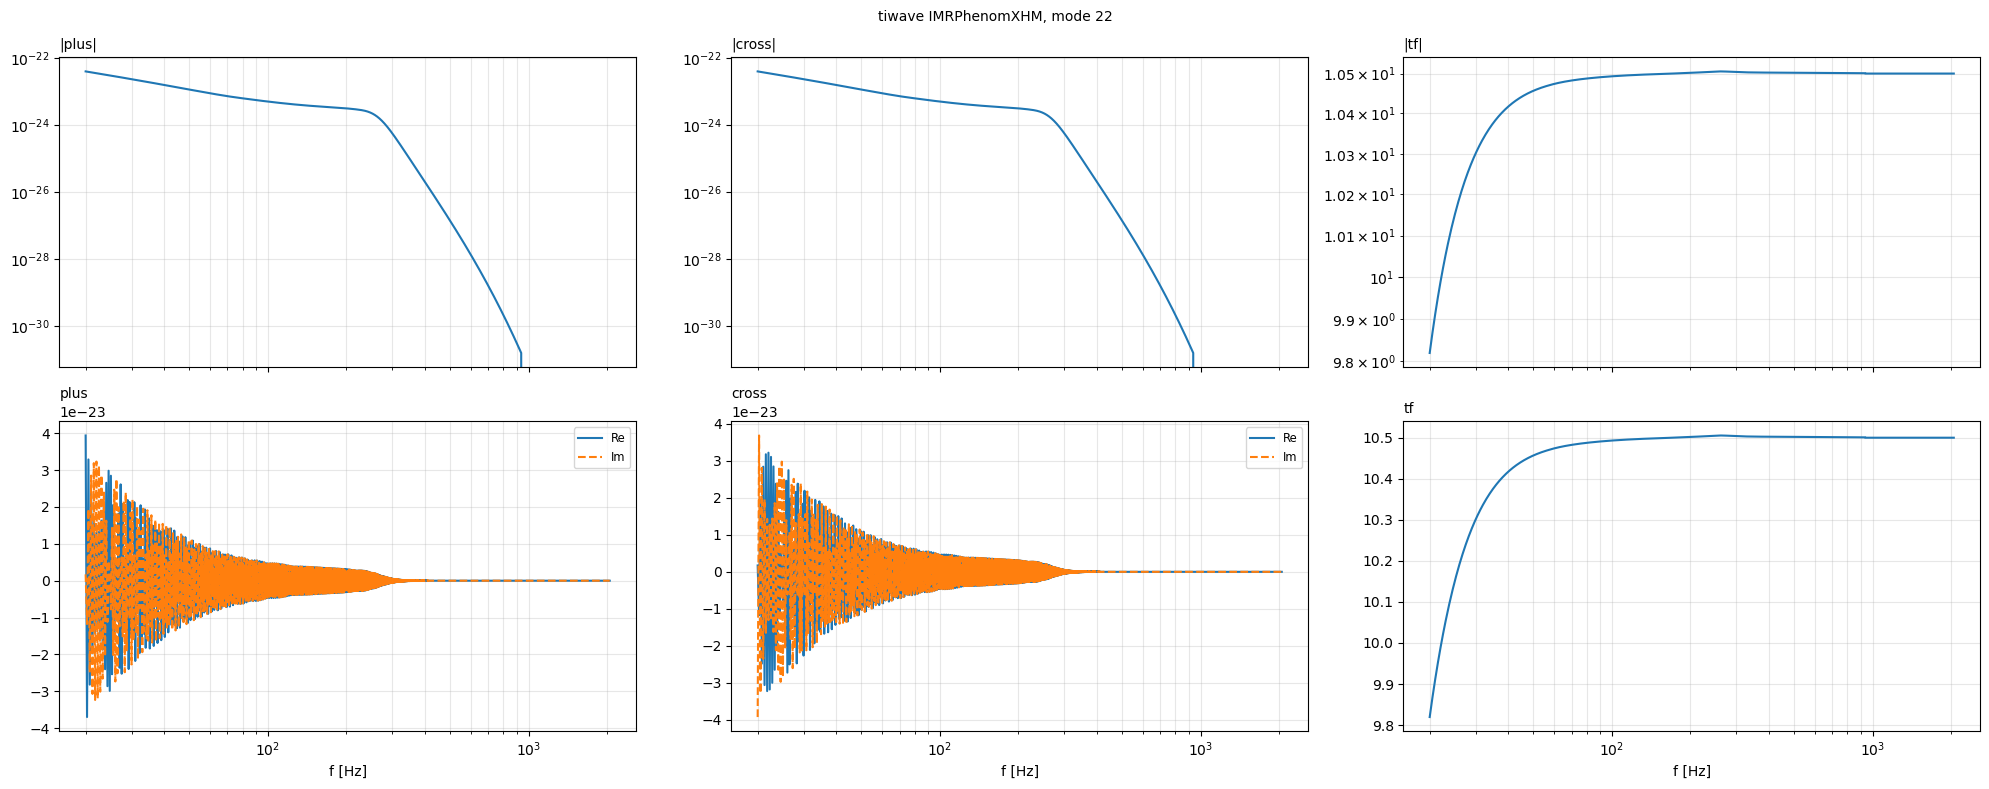

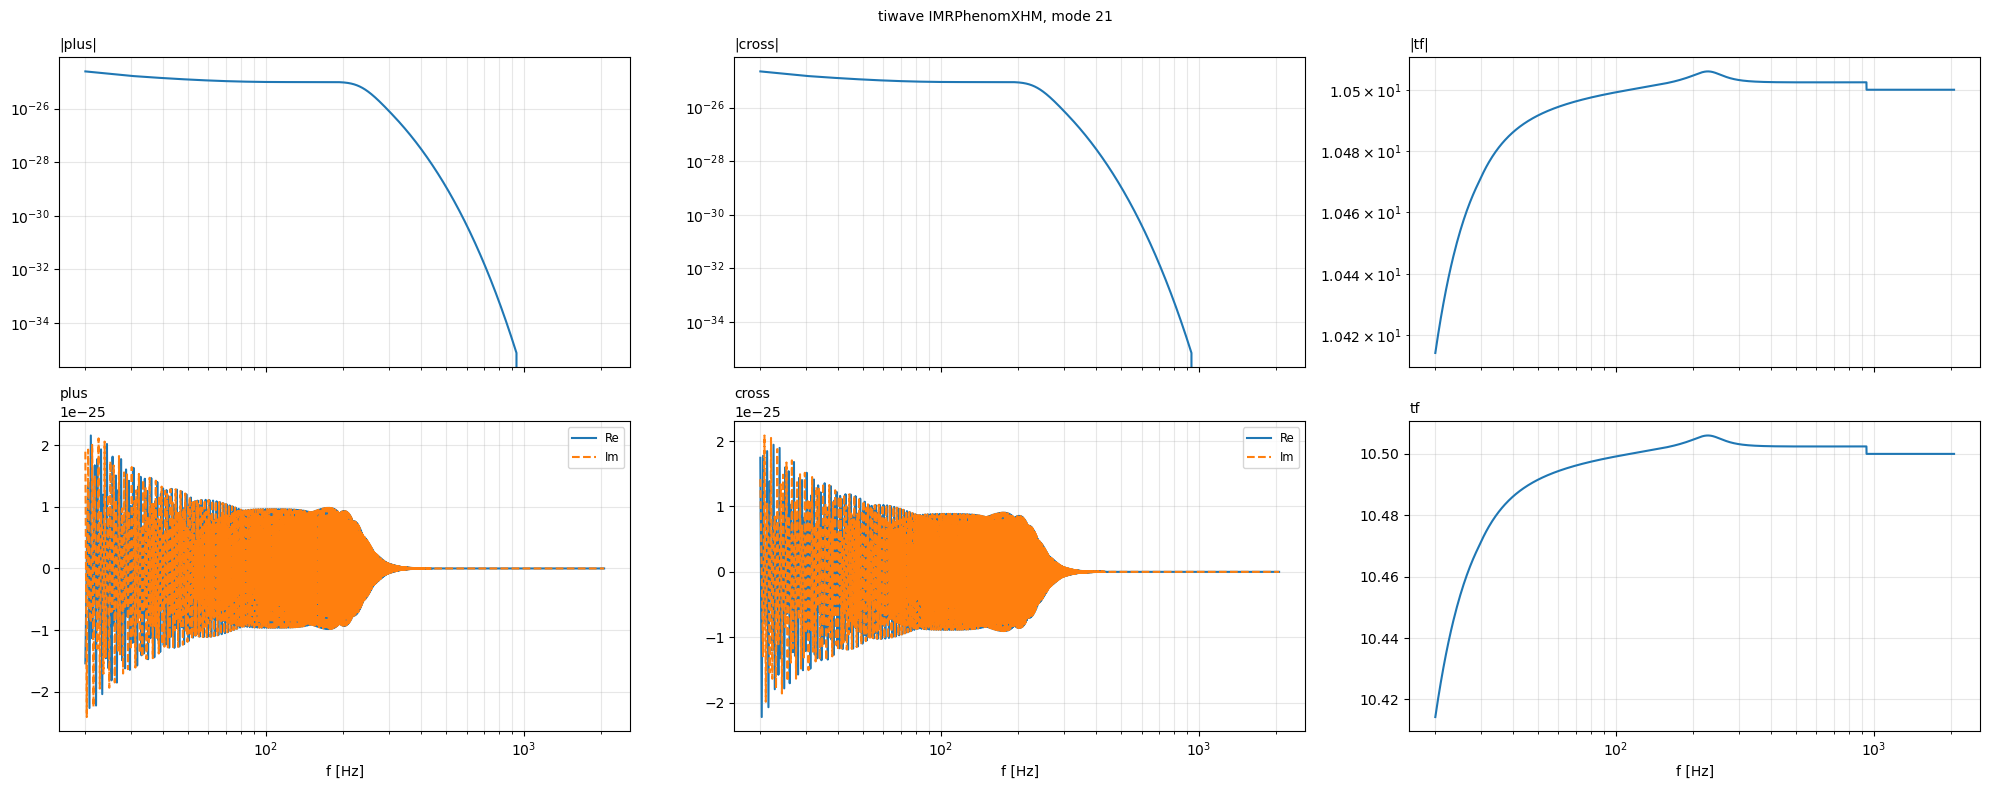

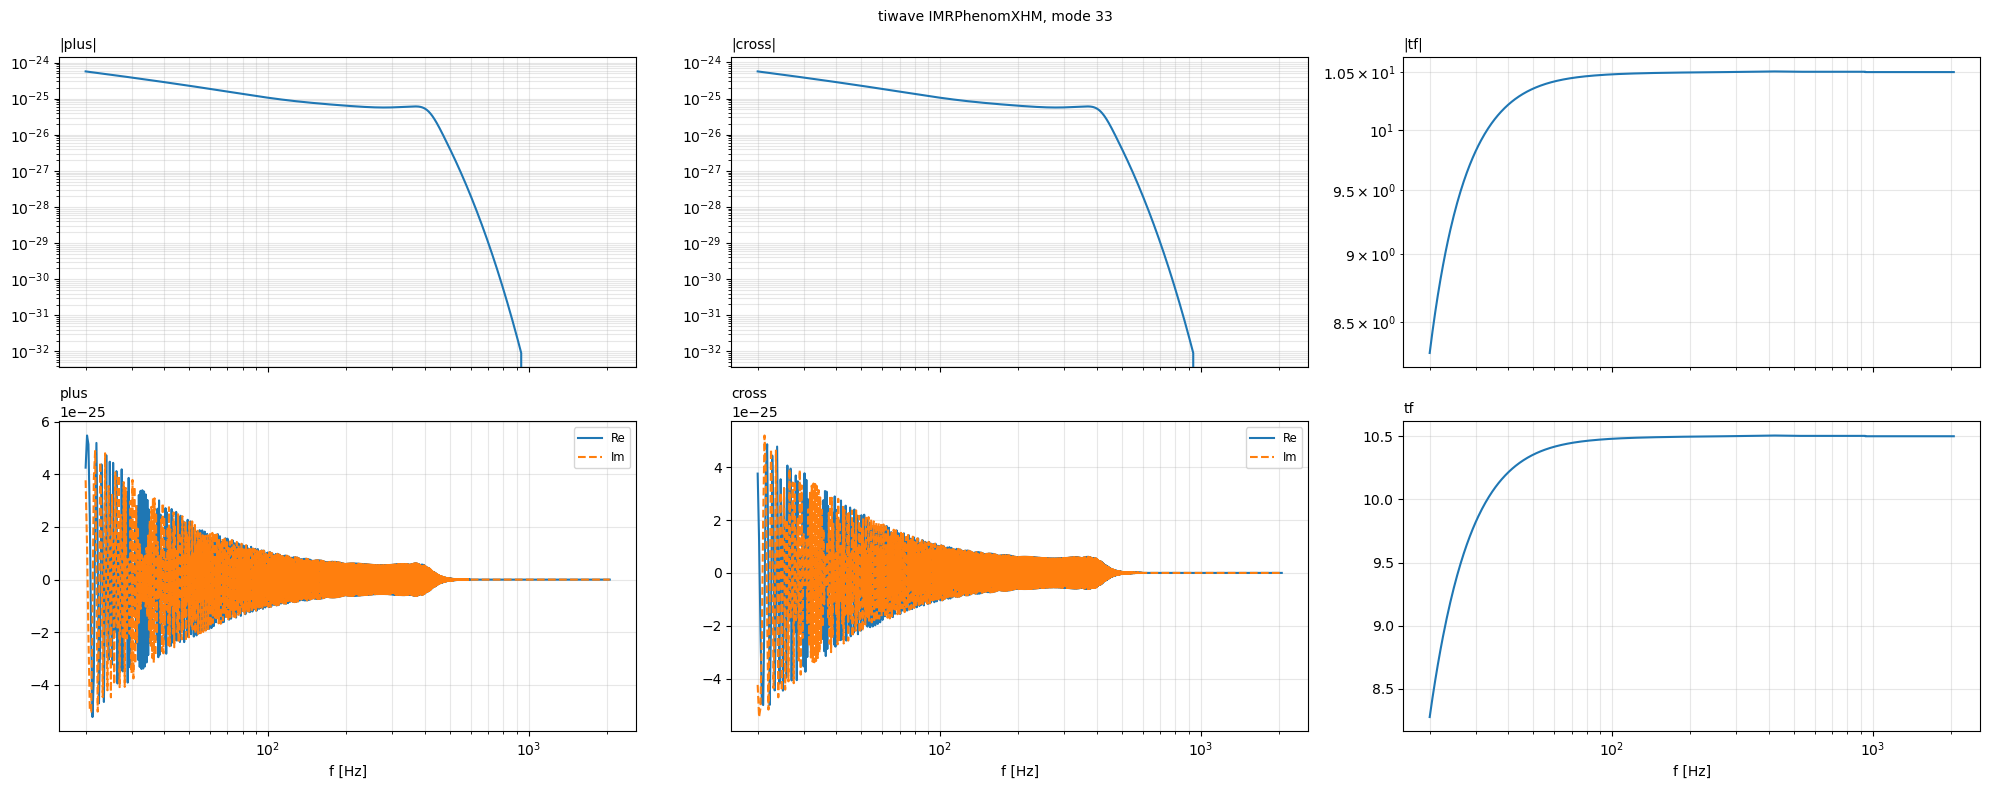

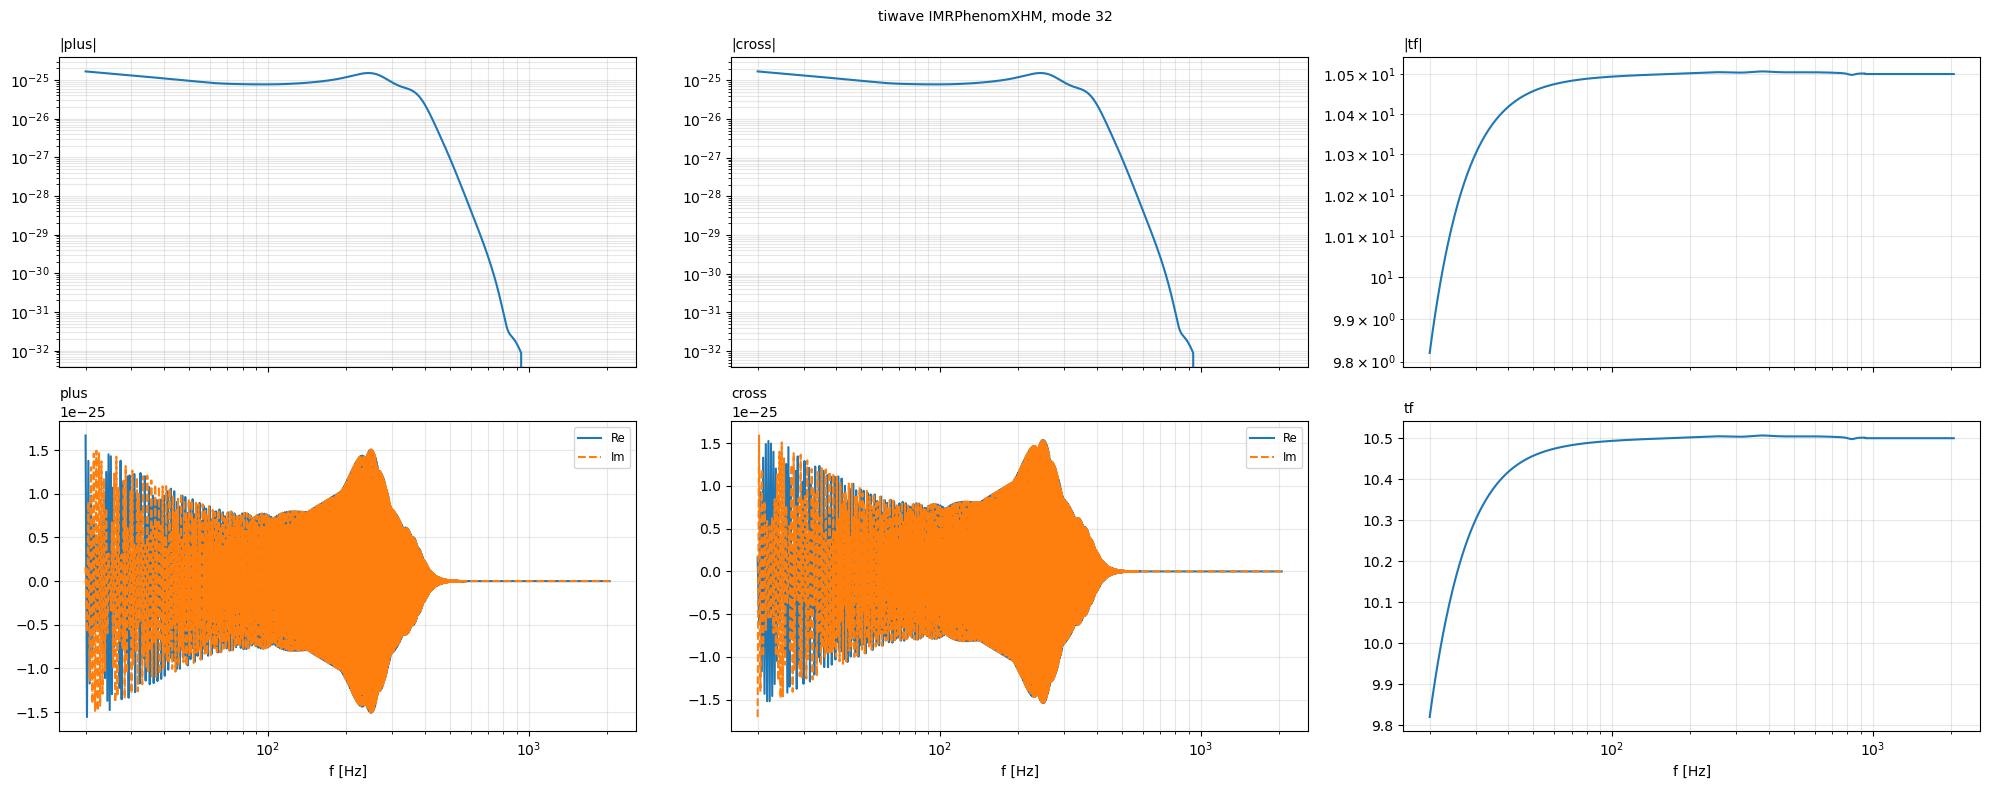

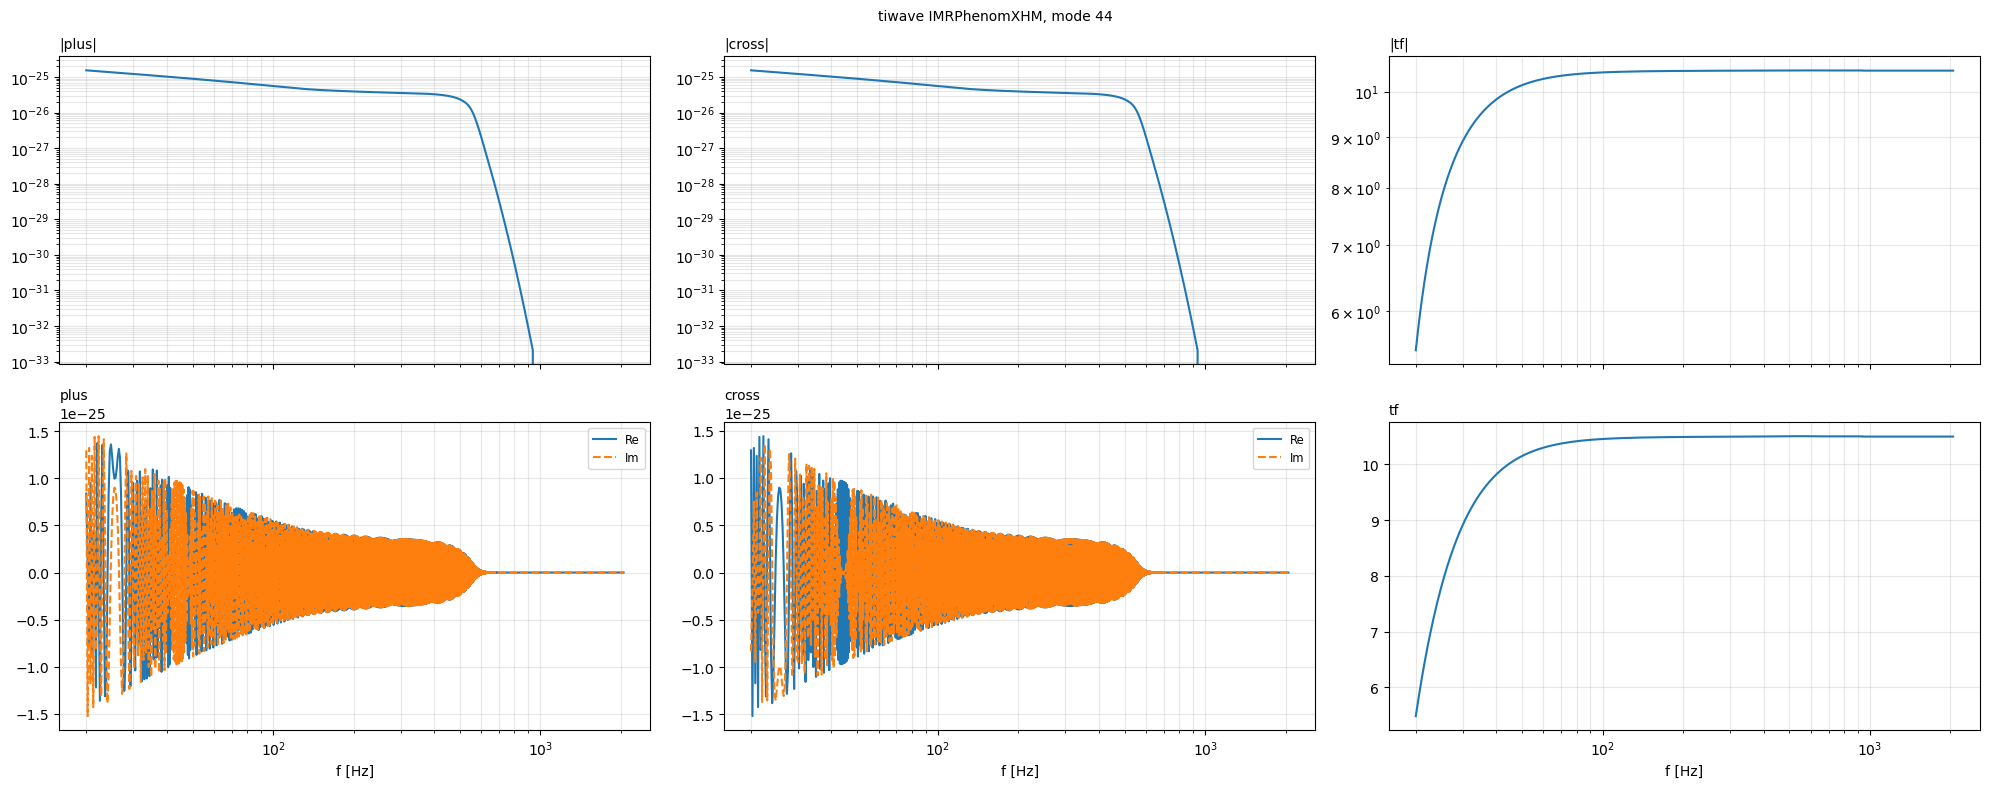

In [11]:
for mode in all_modes:
    fig, axs = plt.subplots(2, 3, figsize=(20, 8), sharex=True)
    fig.suptitle(f"tiwave IMRPhenomXHM, mode {mode}", fontsize="medium")

    # |plus|
    axs[0, 0].loglog(freqs, np.abs(wf_ti_hm[mode]["plus"]))
    axs[0, 0].set_title("|plus|", loc="left", fontsize="medium")

    # plus (real and imaginary parts)
    axs[1, 0].semilogx(freqs, wf_ti_hm[mode]["plus"].real, label="Re")
    axs[1, 0].semilogx(freqs, wf_ti_hm[mode]["plus"].imag, ls="dashed", label="Im")
    axs[1, 0].set_title("plus", loc="left", fontsize="medium")
    axs[1, 0].legend(fontsize="small")

    # |cross|
    axs[0, 1].loglog(freqs, np.abs(wf_ti_hm[mode]["cross"]))
    axs[0, 1].set_title("|cross|", loc="left", fontsize="medium")

    # cross (real and imaginary parts)
    axs[1, 1].semilogx(freqs, wf_ti_hm[mode]["cross"].real, label="Re")
    axs[1, 1].semilogx(freqs, wf_ti_hm[mode]["cross"].imag, ls="dashed", label="Im")
    axs[1, 1].set_title("cross", loc="left", fontsize="medium")
    axs[1, 1].legend(fontsize="small")

    # |tf|
    axs[0, 2].loglog(freqs, np.abs(wf_ti_hm[mode]["tf"]))
    axs[0, 2].set_title("|tf|", loc="left", fontsize="medium")

    # tf
    axs[1, 2].semilogx(freqs, wf_ti_hm[mode]["tf"])
    axs[1, 2].set_title("tf", loc="left", fontsize="medium")

    for a in axs.flat:
        a.grid(True, which="both", alpha=0.3)
    for a in axs[1]:
        a.set_xlabel("f [Hz]")
    fig.tight_layout()

In [12]:
params_rp_hm = np.array(
    [
        params["mass_1"],
        params["mass_2"],
        params["chi_1"],
        params["chi_2"],
        params["luminosity_distance"],
        params["coalescence_time"],
        params["reference_phase"],
        params["inclination"],
    ]
)
wf_rp_hm = gen_IMRPhenomXHM_hphctf_modes(freqs, params_rp_hm, fref, modes=high_modes)
display({mode: {key: np.shape(val) for key, val in wf.items()} for mode, wf in wf_rp_hm.items()})


{'22': {'plus': (8113,), 'cross': (8113,), 'tf': (8113,)},
 '21': {'plus': (8113,), 'cross': (8113,), 'tf': (8113,)},
 '33': {'plus': (8113,), 'cross': (8113,), 'tf': (8113,)},
 '32': {'plus': (8113,), 'cross': (8113,), 'tf': (8113,)},
 '44': {'plus': (8113,), 'cross': (8113,), 'tf': (8113,)}}

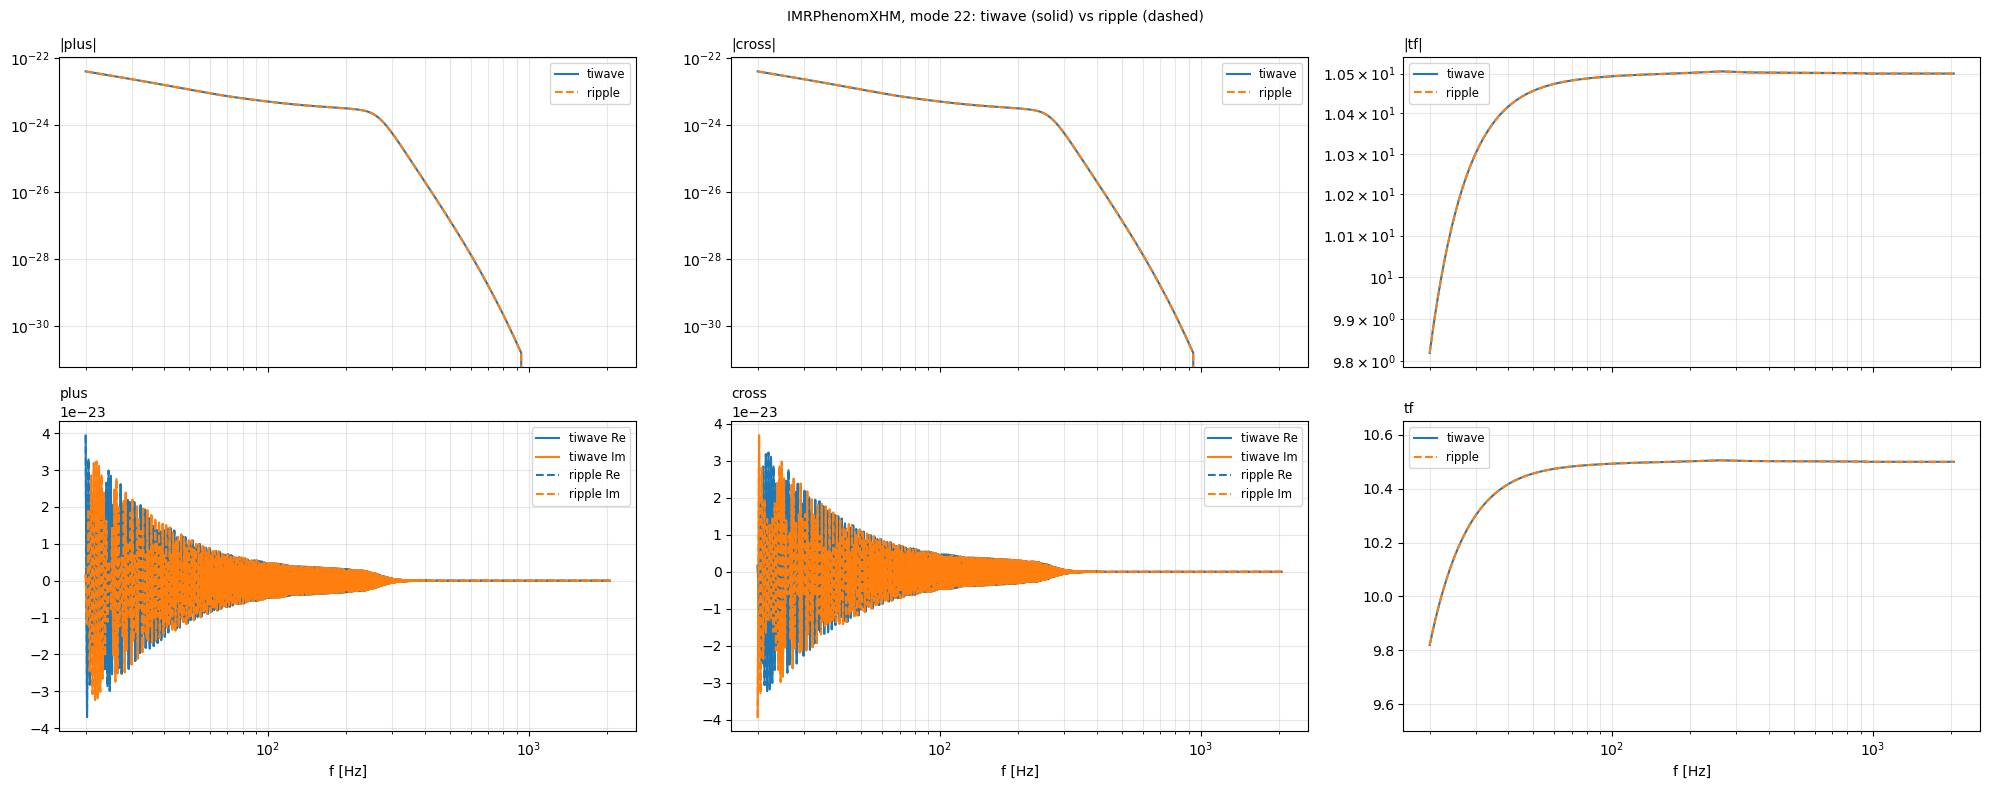

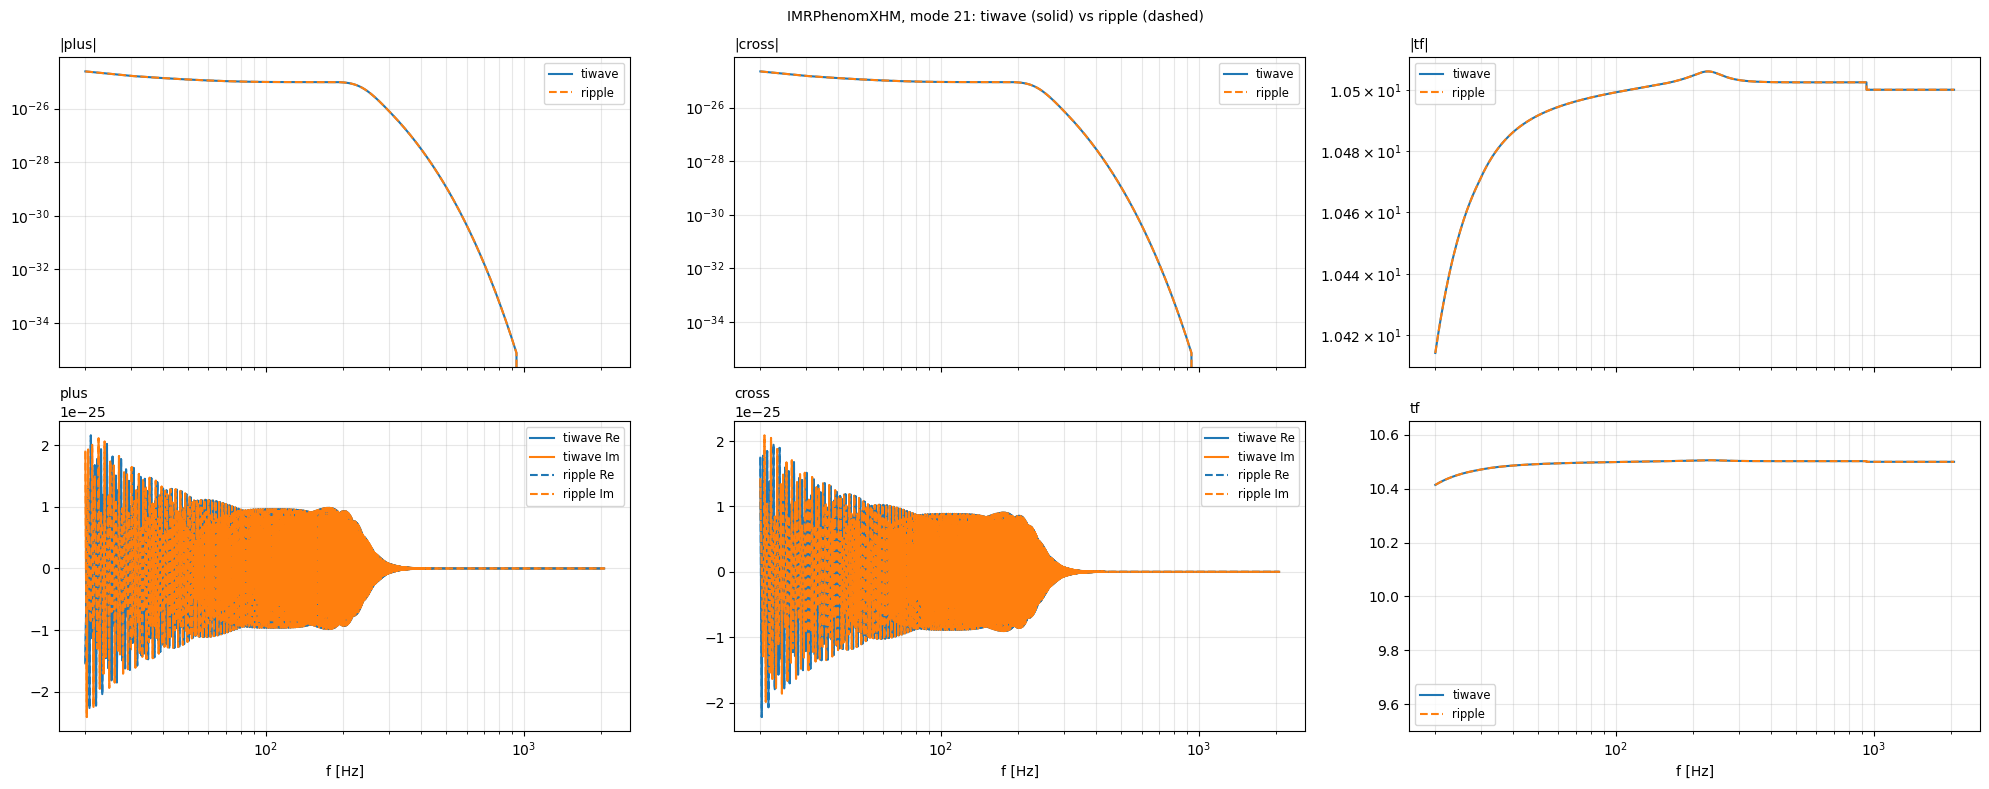

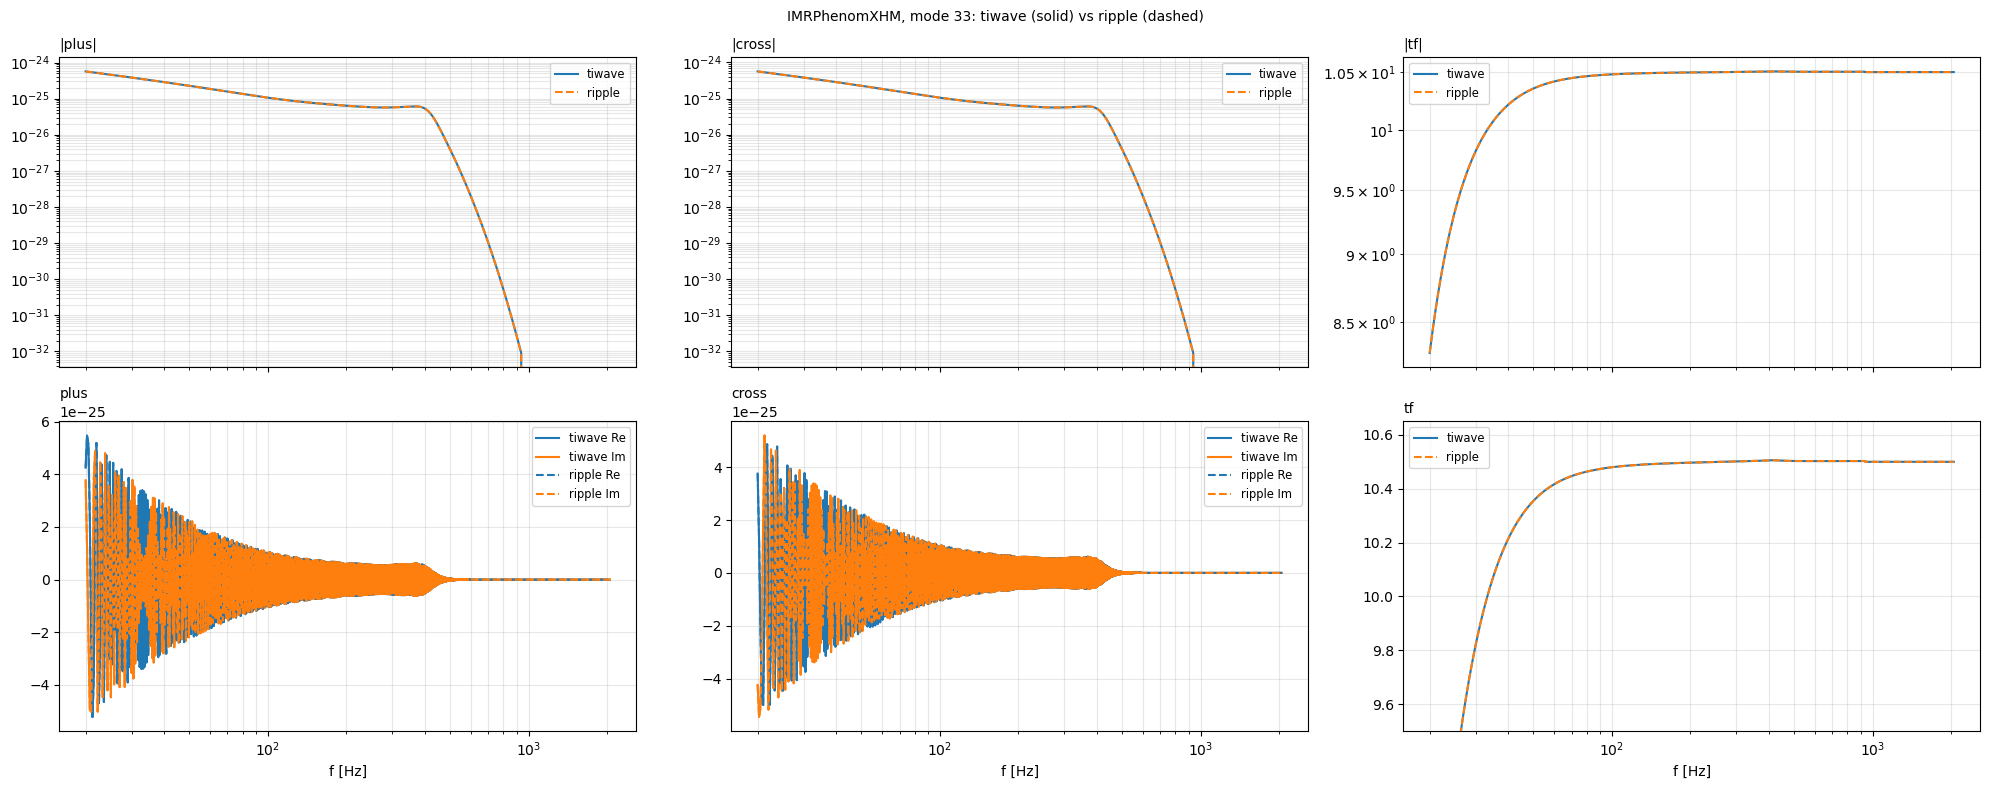

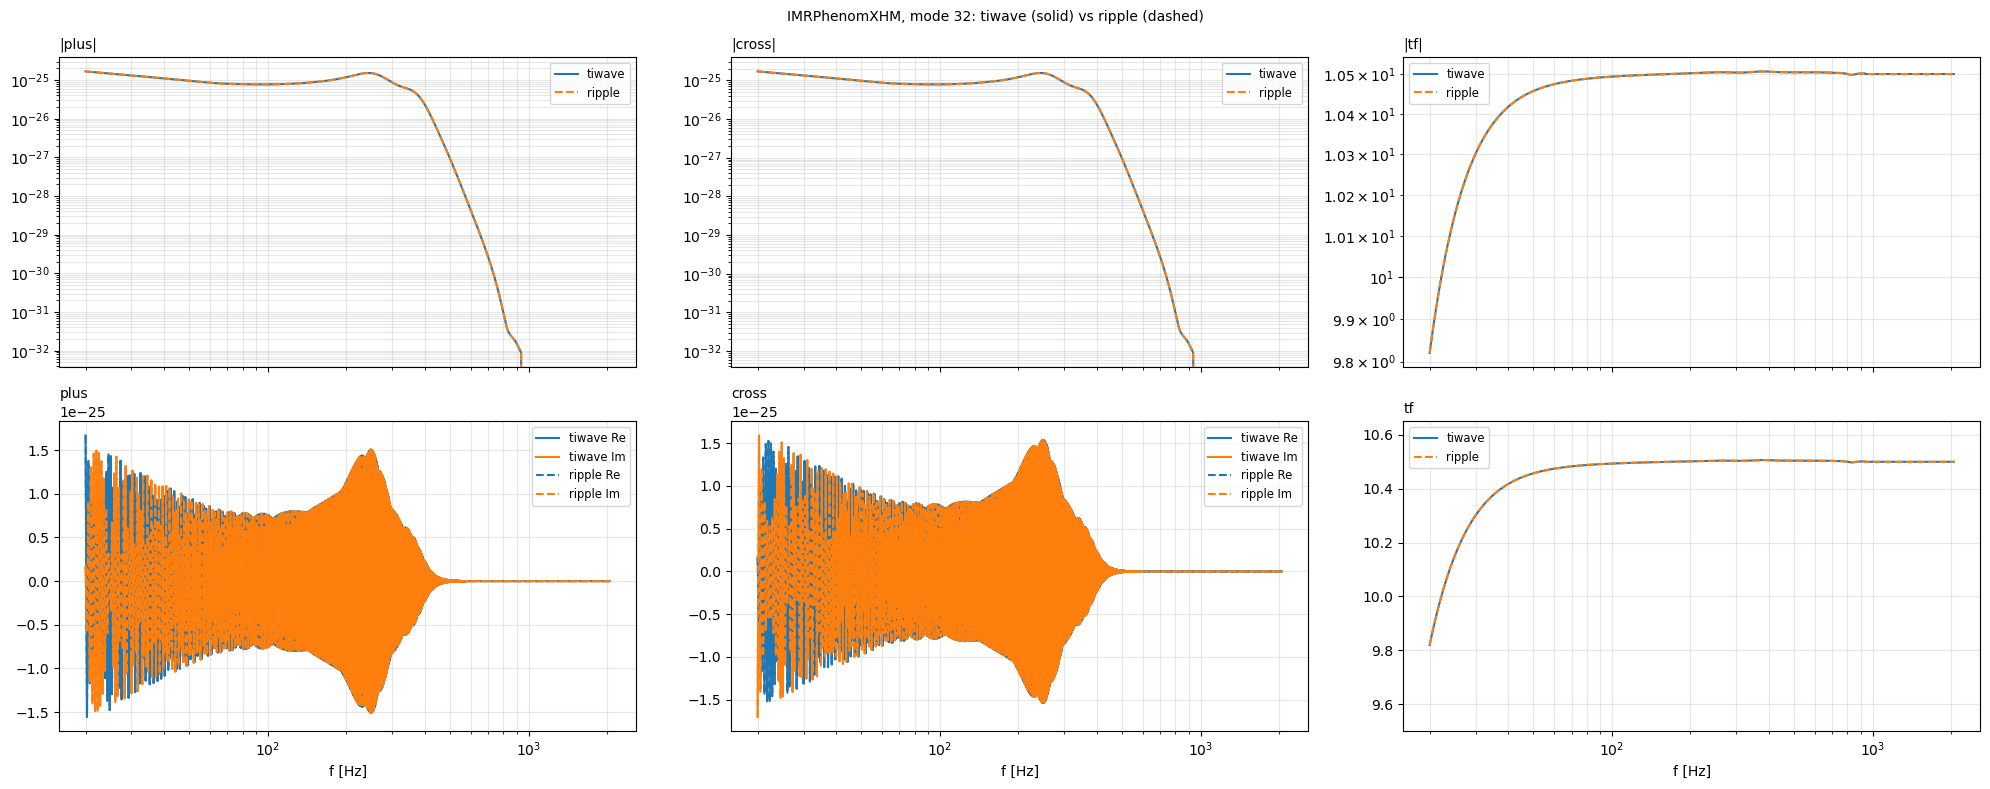

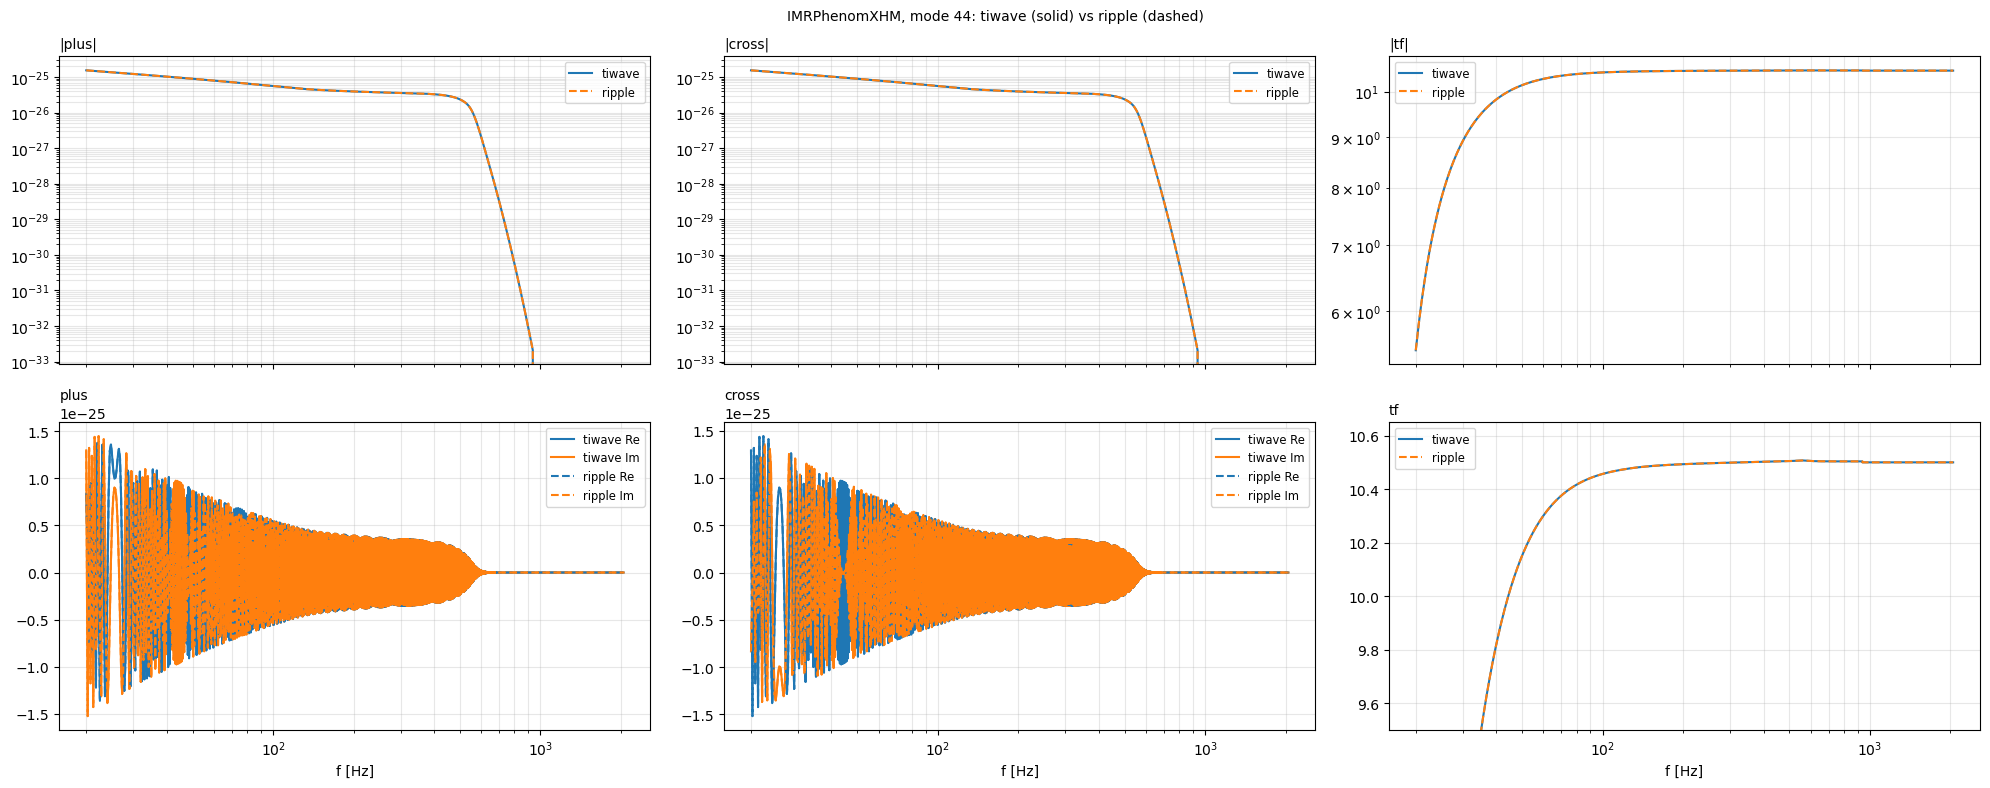

In [13]:
for mode in all_modes:
    fig, axs = plt.subplots(2, 3, figsize=(20, 8), sharex=True)
    fig.suptitle(f"IMRPhenomXHM, mode {mode}: tiwave (solid) vs ripple (dashed)", fontsize="medium")

    # |plus|
    axs[0, 0].loglog(freqs, np.abs(wf_ti_hm[mode]["plus"]), label="tiwave")
    axs[0, 0].loglog(freqs, np.abs(wf_rp_hm[mode]["plus"]), ls="dashed", label="ripple")
    axs[0, 0].set_title("|plus|", loc="left", fontsize="medium")
    axs[0, 0].legend(fontsize="small")

    # plus (real and imaginary parts)
    axs[1, 0].semilogx(freqs, wf_ti_hm[mode]["plus"].real, color="C0", label="tiwave Re")
    axs[1, 0].semilogx(freqs, wf_ti_hm[mode]["plus"].imag, color="C1", label="tiwave Im")
    axs[1, 0].semilogx(freqs, wf_rp_hm[mode]["plus"].real, color="C0", ls="dashed", label="ripple Re")
    axs[1, 0].semilogx(freqs, wf_rp_hm[mode]["plus"].imag, color="C1", ls="dashed", label="ripple Im")
    axs[1, 0].set_title("plus", loc="left", fontsize="medium")
    axs[1, 0].legend(fontsize="small")

    # |cross|
    axs[0, 1].loglog(freqs, np.abs(wf_ti_hm[mode]["cross"]), label="tiwave")
    axs[0, 1].loglog(freqs, np.abs(wf_rp_hm[mode]["cross"]), ls="dashed", label="ripple")
    axs[0, 1].set_title("|cross|", loc="left", fontsize="medium")
    axs[0, 1].legend(fontsize="small")

    # cross (real and imaginary parts)
    axs[1, 1].semilogx(freqs, wf_ti_hm[mode]["cross"].real, color="C0", label="tiwave Re")
    axs[1, 1].semilogx(freqs, wf_ti_hm[mode]["cross"].imag, color="C1", label="tiwave Im")
    axs[1, 1].semilogx(freqs, wf_rp_hm[mode]["cross"].real, color="C0", ls="dashed", label="ripple Re")
    axs[1, 1].semilogx(freqs, wf_rp_hm[mode]["cross"].imag, color="C1", ls="dashed", label="ripple Im")
    axs[1, 1].set_title("cross", loc="left", fontsize="medium")
    axs[1, 1].legend(fontsize="small")

    # |tf|
    axs[0, 2].loglog(freqs, np.abs(wf_ti_hm[mode]["tf"]), label="tiwave")
    axs[0, 2].loglog(freqs, np.abs(wf_rp_hm[mode]["tf"]), ls="dashed", label="ripple")
    axs[0, 2].set_title("|tf|", loc="left", fontsize="medium")
    axs[0, 2].legend(fontsize="small")

    # tf
    axs[1, 2].semilogx(freqs, wf_ti_hm[mode]["tf"], label="tiwave")
    axs[1, 2].semilogx(freqs, wf_rp_hm[mode]["tf"], ls="dashed", label="ripple")
    axs[1, 2].set_title("tf", loc="left", fontsize="medium")
    axs[1, 2].set_ylim(params["coalescence_time"] - 1.0, params["coalescence_time"] + 0.15)
    axs[1, 2].legend(fontsize="small")

    for a in axs.flat:
        a.grid(True, which="both", alpha=0.3)
    for a in axs[1]:
        a.set_xlabel("f [Hz]")
    fig.tight_layout()

In [14]:
sample_num = 100
rng = np.random.default_rng(seed=2026)
params_samples = {
    "chi_1": rng.uniform(-0.99, 0.99, sample_num),
    "chi_2": rng.uniform(-0.99, 0.99, sample_num),
    "inclination": rng.uniform(0.0, np.pi, sample_num),
    "reference_phase": rng.uniform(0.0, 2 * np.pi, sample_num),
    "coalescence_time": rng.uniform(-2, 2, sample_num),
    "chirp_mass": rng.uniform(20, 100, sample_num),
    "mass_ratio": rng.uniform(0.05, 0.99, sample_num),
    "luminosity_distance": np.exp(rng.uniform(np.log(100), np.log(5000), sample_num)),
}
params_samples = bilby.gw.conversion.generate_mass_parameters(params_samples)


In [15]:
# Check ripple vs tiwave IMRPhenomXHM on the 100 random samples

def tiwave_xhm_modes(p):
    """tiwave per-mode plus/cross/tf; apply the tc shift manually."""
    wf_tiwave_hm.update_waveform(p)
    raw = wf_tiwave_hm.waveform_container.to_numpy()
    shift = np.exp(-1j * 2 * np.pi * freqs * p["coalescence_time"])
    out = {}
    for mode in all_modes:
        out[mode] = {
            "plus": (raw[mode]["plus"][:, 0] + 1j * raw[mode]["plus"][:, 1]) * shift,
            "cross": (raw[mode]["cross"][:, 0] + 1j * raw[mode]["cross"][:, 1]) * shift,
            "tf": np.array(raw[mode]["tf"]) + p["coalescence_time"],
        }
    return out


@jax.jit
def ripple_xhm_modes(theta):
    return gen_IMRPhenomXHM_hphctf_modes(freqs, theta, fref, modes=high_modes)


worst_array = {mode: np.zeros((sample_num, 3)) for mode in all_modes}  # (sample_num, [plus rel, cross rel, tf rel])

for i in range(sample_num):
    p = {k: v[i] for k, v in params_samples.items()}
    ti = tiwave_xhm_modes(p)
    theta = np.array(
        [
            p["mass_1"],
            p["mass_2"],
            p["chi_1"],
            p["chi_2"],
            p["luminosity_distance"],
            p["coalescence_time"],
            p["reference_phase"],
            p["inclination"],
        ]
    )
    rp = ripple_xhm_modes(theta)

    for mode in all_modes:
        worst_array[mode][i][0] = np.max(
            np.abs(
                np.divide(
                    rp[mode]["plus"] - ti[mode]["plus"],
                    ti[mode]["plus"],
                    np.zeros_like(ti[mode]["plus"]),
                    where=(ti[mode]["plus"] != 0.0 + 1j*0.0)
                    )
                )
        )
        worst_array[mode][i][1] = np.max(
            np.abs(
                np.divide(
                    rp[mode]["cross"] - ti[mode]["cross"],
                    ti[mode]["cross"],
                    np.zeros_like(ti[mode]["cross"]),
                    where=(ti[mode]["cross"] != 0.0 + 1j*0.0)
                    )
                )
        )
        worst_array[mode][i][2] = np.max(
            np.abs(
                np.divide(
                    rp[mode]["tf"] - ti[mode]["tf"],
                    ti[mode]["tf"],
                    np.zeros_like(ti[mode]["tf"]),
                    where=(ti[mode]["tf"] != 0.0)
                    )
                )
        )

# per-mode statistics over the 100 samples (max/mean/median of the per-sample worst rel diff)
for mode in all_modes:
    vals = worst_array[mode]
    parts = []
    for k, name in enumerate(("plus", "cross", "tf")):
        v = vals[:, k]
        parts.append(
            f"{name}: max={np.max(v):.3e} mean={np.mean(v):.3e} median={np.median(v):.3e}"
        )
    print(f"mode {mode}   " + "   ".join(parts))

mode 22   plus: max=4.896e-10 mean=1.027e-11 median=1.130e-12   cross: max=4.896e-10 mean=1.027e-11 median=1.130e-12   tf: max=1.555e-11 mean=1.716e-13 median=1.547e-15
mode 21   plus: max=2.228e-12 mean=2.585e-13 median=1.674e-13   cross: max=2.228e-12 mean=2.586e-13 median=1.678e-13   tf: max=1.985e-12 mean=2.037e-14 median=2.201e-16
mode 33   plus: max=3.165e-11 mean=2.170e-12 median=5.653e-13   cross: max=3.165e-11 mean=2.170e-12 median=5.653e-13   tf: max=5.616e-12 mean=9.073e-14 median=9.592e-16
mode 32   plus: max=1.234e-02 mean=2.767e-04 median=1.176e-04   cross: max=1.234e-02 mean=2.767e-04 median=1.176e-04   tf: max=8.197e-03 mean=8.523e-05 median=6.698e-07
mode 44   plus: max=1.373e-11 mean=8.524e-13 median=4.946e-13   cross: max=1.373e-11 mean=8.524e-13 median=4.944e-13   tf: max=8.951e-12 mean=1.987e-13 median=1.262e-15
